# When the confounder is unobserved: instruments and discontinuities

Every method so far needs all confounders measured. This notebook covers the two classic designs that work **without**
conditional ignorability, each by finding a source of variation in the treatment that is "as good as random":

| design | source of as-good-as-random variation | identifying assumption | course example |
|---|---|---|---|
| instrumental variables | a variable $Z$ that shifts $T$ but has no other path to $Y$ | relevance, exclusion, independence | hotel pricing (Lecture 1) |
| regression discontinuity | a threshold rule $T = \mathbb{1}[\text{running variable} \ge a]$ | continuity of $E[Y(t) \mid \text{running}]$ at $a$ | treat iff age $\ge 6$ |

| § | Idea |
|---|---|
| 1 | The pricing problem: regression gets the demand curve wrong |
| 2 | Linear IV: Wald ratio and two-stage least squares |
| 3 | What breaks IV: weak instruments and exclusion violations |
| 4 | Nonparametric IV (the problem DeepIV and DeepGMM solve) and the revenue-maximizing price |
| 5 | RDD: a jump at the cutoff |
| 6 | Bandwidth: bias vs variance, chosen by cross-validation |
| 7 | Global polynomials and placebo cutoffs |
| 8 | **slider:** RDD bandwidth |

Code: [`src/iv.py`](../src/iv.py), [`src/rdd.py`](../src/rdd.py).

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as w

from src import iv, rdd

plt.rcParams["figure.dpi"] = 100

## 1. The pricing problem

A hotel's price $P$ and rooms sold $Y$, with unobserved demand $D$ pushing both up, and the hotel's cost $C$ shifting the
price. The true demand curve $h(p)$ (rooms sold if *we set* the price to $p$) is decreasing.

```
      D (unobserved)
     ↙   ↘
C → P  →  Y
```

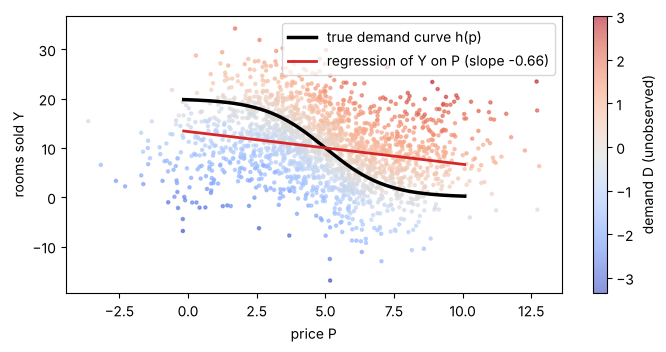

In [2]:
dp = iv.make_pricing(seed=0)
grid = np.linspace(np.quantile(dp.P, 0.02), np.quantile(dp.P, 0.98), 200)
b = iv.naive_ols(dp.P, dp.Y)
fig, ax = plt.subplots(figsize=(8, 3.6))
sub = np.random.default_rng(0).choice(len(dp.P), 2000, replace=False)
sc = ax.scatter(dp.P[sub], dp.Y[sub], c=dp.D[sub], cmap="coolwarm", s=5, alpha=0.6)
plt.colorbar(sc, label="demand D (unobserved)")
ax.plot(grid, iv.h_true(grid), "k", lw=2.5, label="true demand curve h(p)")
ax.plot(grid, b[0] + b[1] * grid, "tab:red", lw=2, label=f"regression of Y on P (slope {b[1]:+.2f})")
ax.set_xlabel("price P"); ax.set_ylabel("rooms sold Y"); ax.legend(loc="upper right"); plt.show()

High prices coincide with high-demand days, so the regression line is far flatter than the demand curve: it
*underestimates* how much sales fall when we raise the price, and a revenue optimizer built on it would overprice.
Colouring by demand (which the hotel cannot do) shows the problem; this is the first example of the course.

## 2. Linear IV

The cost $C$ is an instrument: (1) **relevance**, $C$ moves $P$; (2) **exclusion**, $C$ affects $Y$ only through $P$;
(3) **independence**, $C \perp\!\!\!\perp D$. Then the variation in $P$ *caused by* $C$ is free of demand, and for a
linear model $Y = \alpha + \beta P + \text{error}$:

$$\beta_{IV} = \frac{\text{Cov}(Y, C)}{\text{Cov}(P, C)} \qquad \text{(Wald ratio)}.$$

Two-stage least squares computes the same thing as "regress $P$ on $C$, then regress $Y$ on the fitted $\hat P$".

In [3]:
print(f"OLS slope       {b[1]:+.3f}")
print(f"Wald / IV slope {iv.wald(dp.C, dp.P, dp.Y):+.3f}")
print(f"2SLS slope      {iv.tsls(dp.Y, dp.P, dp.C)[1]:+.3f}")
# what linear IV is estimating: the best linear approximation of h, weighted by how C moves P
Phat = np.polyval(np.polyfit(dp.C, dp.P, 1), dp.C)
print(f"slope of h along the instrument-driven variation: {np.polyfit(Phat, iv.h_true(dp.P), 1)[0]:+.3f}")

OLS slope       -0.664
Wald / IV slope -2.623
2SLS slope      -2.623
slope of h along the instrument-driven variation: -2.561


IV recovers a strongly negative slope. Since $h$ is nonlinear, "the" slope is a weighted average of $h'(p)$, weighted by
where the instrument moves the price (the last line), not the full curve.

## 3. What breaks IV

**Weak instruments.** If the cost barely moves the price, $\text{Cov}(P, C)$ is tiny and noisy, and the ratio becomes
erratic: with 2000 hotels-nights the estimate can land anywhere, including on the wrong side of zero. **Exclusion violations.** If cost affects sales through another path (cheaper
hotels are also shabbier), IV converges to the wrong number no matter how much data we have.

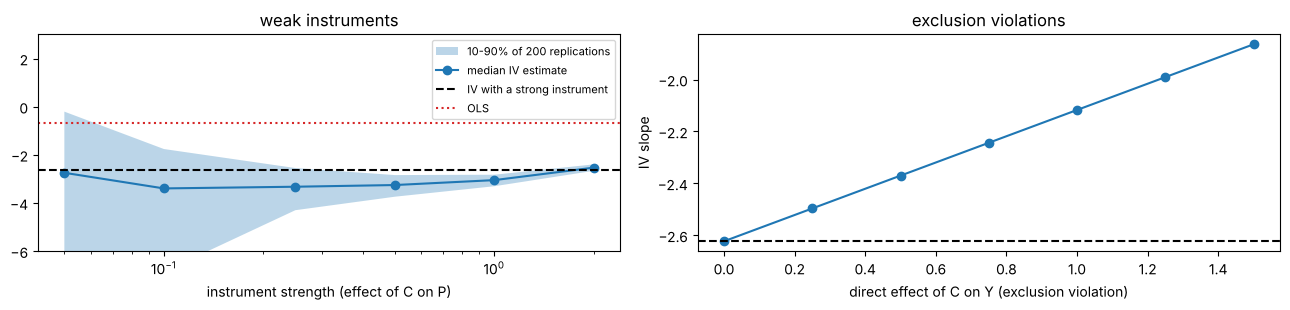

In [4]:
strengths = [0.05, 0.1, 0.25, 0.5, 1.0, 2.0]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.2))
res = []
for s in strengths:
    est = [iv.wald(*iv.make_pricing(n=2000, seed=r, instrument_strength=s)[:3]) for r in range(200)]
    res.append(np.percentile(est, [10, 50, 90]))
res = np.array(res)
ax[0].fill_between(strengths, res[:, 0], res[:, 2], alpha=0.3, label="10-90% of 200 replications")
ax[0].plot(strengths, res[:, 1], "o-", label="median IV estimate")
ax[0].axhline(iv.wald(dp.C, dp.P, dp.Y), color="k", ls="--", label="IV with a strong instrument")
ax[0].axhline(b[1], color="tab:red", ls=":", label="OLS")
ax[0].set_xscale("log"); ax[0].set_ylim(-6, 3); ax[0].set_xlabel("instrument strength (effect of C on P)"); ax[0].legend(fontsize=8)
ax[0].set_title("weak instruments")
viol = np.linspace(0, 1.5, 7); ests = []
for g in viol:
    d2 = iv.make_pricing(seed=0)
    Y2 = d2.Y + g * d2.C                     # a direct effect of cost on sales
    ests.append(iv.wald(d2.C, d2.P, Y2))
ax[1].plot(viol, ests, "o-"); ax[1].axhline(iv.wald(dp.C, dp.P, dp.Y), color="k", ls="--")
ax[1].set_xlabel("direct effect of C on Y (exclusion violation)"); ax[1].set_ylabel("IV slope"); ax[1].set_title("exclusion violations")
plt.tight_layout(); plt.show()

Neither failure is visible in the data alone: exclusion is an assumption about the graph (Lecture "DAGs"), and the
first-stage strength should always be reported.

## 4. Nonparametric IV: the whole demand curve

To set a price we need $h(p)$ everywhere, not one slope. IV identifies $h$ through an integral equation:

$$E[Y \mid C] = E[h(P) \mid C] = \int h(p)\, dF(p \mid C).$$

* **Sieve 2SLS** (here): expand $h$ in a spline basis, predict every basis function from $C$ (stage 1), regress $Y$ on
  the predictions (stage 2).
* **DeepIV** (Hartford+ 2017): stage 1 is a mixture density network for $P \mid C, X$; stage 2 trains a network $h$ to
  minimize $\big(Y - \int h(p)\, d\hat F(p \mid C)\big)^2$ by sampling from the stage-1 model.
* **DeepGMM** (Bennett+ 2019): no density model; find $h$ that satisfies the moment conditions
  $E[(Y - h(P)) f(C)] = 0$ for an adversarially chosen $f$.

The three are interchangeable on this toy; the deep versions matter with high-dimensional $X$ and $C$ (images, text).

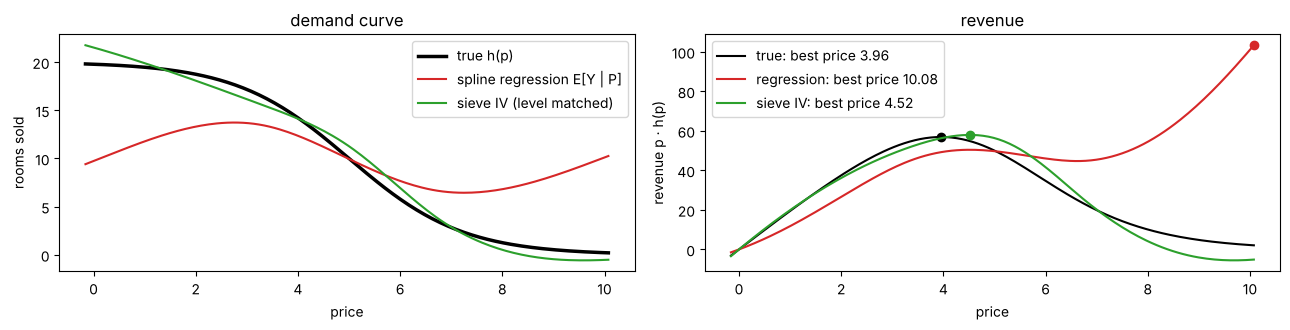

regression: chooses price 10.08; true revenue there 2.1 vs best possible 56.9
  sieve IV: chooses price 4.52; true revenue there 54.8 vs best possible 56.9


In [5]:
g, h_iv = iv.sieve_iv(dp.C, dp.P, dp.Y, p_grid=grid)
_, h_reg = iv.sieve_regression(dp.P, dp.Y, p_grid=grid)
rev = lambda h: grid * h
fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
ax[0].plot(grid, iv.h_true(grid), "k", lw=2.5, label="true h(p)")
ax[0].plot(grid, h_reg, "tab:red", label="spline regression E[Y | P]")
ax[0].plot(grid, h_iv - h_iv.mean() + iv.h_true(grid).mean(), "tab:green", label="sieve IV (level matched)")
ax[0].set_xlabel("price"); ax[0].set_ylabel("rooms sold"); ax[0].legend(); ax[0].set_title("demand curve")
for lab, h, c in [("true", iv.h_true(grid), "k"), ("regression", h_reg, "tab:red"),
                  ("sieve IV", h_iv - h_iv.mean() + iv.h_true(grid).mean(), "tab:green")]:
    r = rev(h); ax[1].plot(grid, r, color=c, label=f"{lab}: best price {grid[np.argmax(r)]:.2f}")
    ax[1].plot(grid[np.argmax(r)], r.max(), "o", color=c)
ax[1].set_xlabel("price"); ax[1].set_ylabel("revenue p · h(p)"); ax[1].legend(); ax[1].set_title("revenue")
plt.tight_layout(); plt.show()
true_best = grid[np.argmax(rev(iv.h_true(grid)))]
for lab, h in [("regression", h_reg), ("sieve IV", h_iv - h_iv.mean() + iv.h_true(grid).mean())]:
    p = grid[np.argmax(rev(h))]
    print(f"{lab:>10}: chooses price {p:.2f}; true revenue there {p * iv.h_true(p):.1f} vs best possible {true_best * iv.h_true(true_best):.1f}")

A caveat the plot hides: IV pins down $h$ only up to what the instrument can move. Without a normalization the level of
$h$ is not identified here (we matched the mean), and where the instrument rarely pushes the price the curve is poorly
determined. That is a positivity condition in disguise.

## 5. Regression discontinuity: treat iff age $\ge 6$

Severity is unobserved, so the graph has an open backdoor path and no adjustment set exists. But the doctors follow a
strict rule. If the potential outcomes are **continuous in age**, patients just below and just above 6 are comparable,
and

$$\tau(6) = \lim_{a \downarrow 6} E[Y \mid \text{age} = a] - \lim_{a \uparrow 6} E[Y \mid \text{age} = a].$$

No ignorability needed, but the price is locality: we learn the effect *at the cutoff* only.

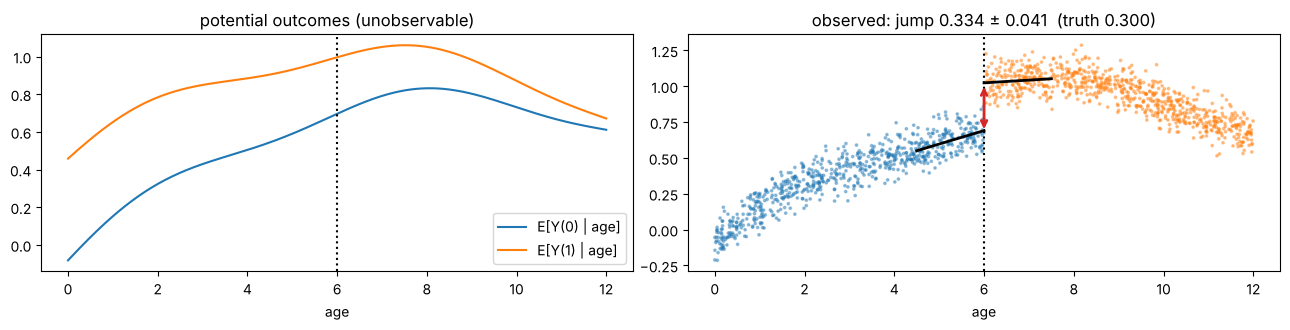

In [6]:
dr = rdd.make_rdd(seed=0)
ages = np.linspace(0, 12, 400)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
ax[0].plot(ages, rdd.mu0(ages), color="tab:blue", label="E[Y(0) | age]"); ax[0].plot(ages, rdd.mu1(ages), color="tab:orange", label="E[Y(1) | age]")
ax[0].axvline(6, color="k", ls=":"); ax[0].set_xlabel("age"); ax[0].legend(); ax[0].set_title("potential outcomes (unobservable)")
ax[1].scatter(dr.age, dr.Y, c=np.where(dr.T == 1, "tab:orange", "tab:blue"), s=3, alpha=0.4)
est, se, (yl, yr) = rdd.local_linear(dr.age, dr.Y, 6, h=1.5)
for side, (lo, hi), y0 in [("L", (4.5, 6), yl), ("R", (6, 7.5), yr)]:
    m = (dr.age >= lo) & (dr.age < hi); coef = np.polyfit(dr.age[m], dr.Y[m], 1)
    ax[1].plot([lo, hi], np.polyval(coef, [lo, hi]), "k", lw=2)
ax[1].annotate("", xy=(6, yr), xytext=(6, yl), arrowprops=dict(arrowstyle="<->", color="tab:red", lw=2))
ax[1].axvline(6, color="k", ls=":"); ax[1].set_xlabel("age"); ax[1].set_title(f"observed: jump {est:.3f} ± {1.96 * se:.3f}  (truth {rdd.true_effect():.3f})")
plt.tight_layout(); plt.show()

## 6. Bandwidth: a bias-variance trade-off you can cross-validate

A wide window uses more data (low variance) but lets curvature leak into the boundary prediction (bias). The estimand is
a pair of predictions, so classic ML tools apply. Imbens & Lemieux's criterion predicts each point near the cutoff from
data on its own side *further from the cutoff*, which mimics the boundary extrapolation the estimator makes.

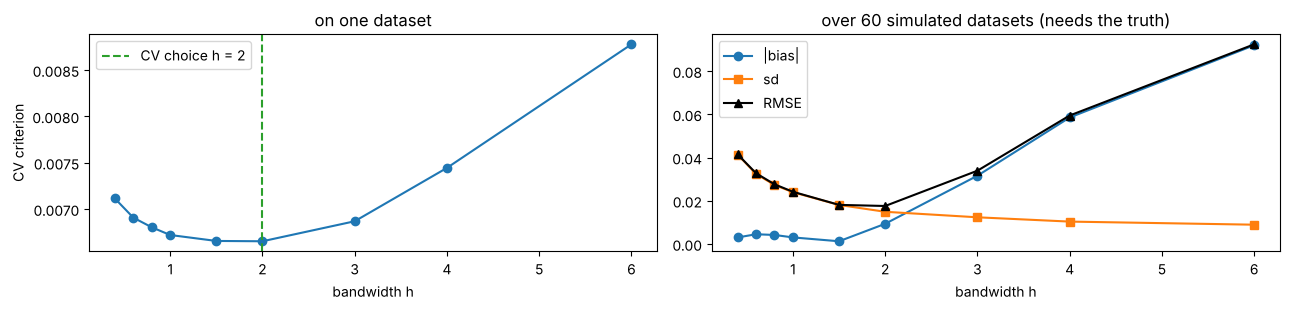

In [7]:
hs = np.array([0.4, 0.6, 0.8, 1.0, 1.5, 2.0, 3.0, 4.0, 6.0])
cv = rdd.cv_bandwidth(dr.age, dr.Y, 6, hs)
mc = []
for h in hs:
    e = []
    for s in range(60):
        dd = rdd.make_rdd(seed=s)
        e.append(rdd.local_linear(dd.age, dd.Y, 6, h)[0])
    mc.append((np.mean(e) - rdd.true_effect(), np.std(e)))
mc = np.array(mc)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.2))
ax[0].plot(hs, cv, "o-"); ax[0].axvline(hs[np.argmin(cv)], color="tab:green", ls="--", label=f"CV choice h = {hs[np.argmin(cv)]:g}")
ax[0].set_xlabel("bandwidth h"); ax[0].set_ylabel("CV criterion"); ax[0].legend(); ax[0].set_title("on one dataset")
ax[1].plot(hs, np.abs(mc[:, 0]), "o-", label="|bias|"); ax[1].plot(hs, mc[:, 1], "s-", label="sd")
ax[1].plot(hs, np.sqrt(mc[:, 0] ** 2 + mc[:, 1] ** 2), "k^-", label="RMSE")
ax[1].set_xlabel("bandwidth h"); ax[1].legend(); ax[1].set_title("over 60 simulated datasets (needs the truth)")
plt.tight_layout(); plt.show()

## 7. Global polynomials and placebo cutoffs

Two standard checks. A global high-order polynomial on each side is a tempting alternative; its boundary values swing
with the degree (Lee & Card's misspecification concern). And at **placebo cutoffs**, where nothing happens, the
estimator should find no jump.

In [8]:
print("global polynomial on each side, by degree:")
for k in range(0, 7):
    print(f"  degree {k}: {rdd.global_polynomial(dr.age, dr.Y, 6, k):+.3f}")
print(f"local linear, CV bandwidth: {rdd.local_linear(dr.age, dr.Y, 6, hs[np.argmin(cv)])[0]:+.3f}   truth {rdd.true_effect():+.3f}")
print("\nplacebo cutoffs (true jump 0), using only data on one side of the real cutoff:")
for c in [2.5, 3.5, 8.5, 9.5]:
    m = (dr.age < 6) if c < 6 else (dr.age >= 6)
    e, s, _ = rdd.local_linear(dr.age[m], dr.Y[m], c, 1.5)
    print(f"  cutoff {c}: {e:+.3f} ± {1.96 * s:.3f}")

global polynomial on each side, by degree:
  degree 0: +0.543
  degree 1: +0.401
  degree 2: +0.383
  degree 3: +0.287
  degree 4: +0.321
  degree 5: +0.356
  degree 6: +0.346
local linear, CV bandwidth: +0.333   truth +0.300

placebo cutoffs (true jump 0), using only data on one side of the real cutoff:
  cutoff 2.5: -0.022 ± 0.039
  cutoff 3.5: +0.010 ± 0.037
  cutoff 8.5: -0.021 ± 0.032
  cutoff 9.5: -0.027 ± 0.034


## 8. Slider: the bandwidth

In [9]:
def bandwidth(h=1.5):
    est, se, (yl, yr) = rdd.local_linear(dr.age, dr.Y, 6, h)
    fig, ax = plt.subplots(figsize=(9, 3.2))
    inwin = np.abs(dr.age - 6) < h
    ax.scatter(dr.age[~inwin], dr.Y[~inwin], s=3, color="0.8")
    ax.scatter(dr.age[inwin], dr.Y[inwin], s=4, c=np.where(dr.T[inwin] == 1, "tab:orange", "tab:blue"))
    ax.plot(ages, rdd.mu0(ages), "tab:blue", lw=0.8); ax.plot(ages, rdd.mu1(ages), "tab:orange", lw=0.8)
    ax.plot([6, 6], [yl, yr], "tab:red", lw=3)
    ax.set_title(f"h = {h:g}: estimate {est:.3f} ± {1.96 * se:.3f}  (truth {rdd.true_effect():.3f}, {inwin.sum()} points used)")
    ax.set_xlabel("age"); plt.show()

w.interact(bandwidth, h=w.FloatSlider(value=1.5, min=0.3, max=6.0, step=0.1));

interactive(children=(FloatSlider(value=1.5, description='h', max=6.0, min=0.3), Output()), _dom_classes=('wid…

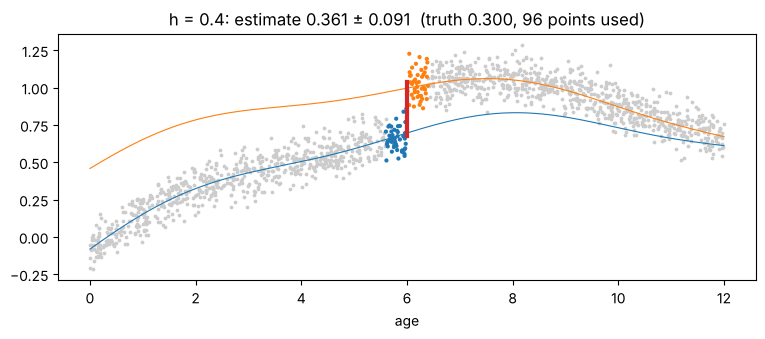

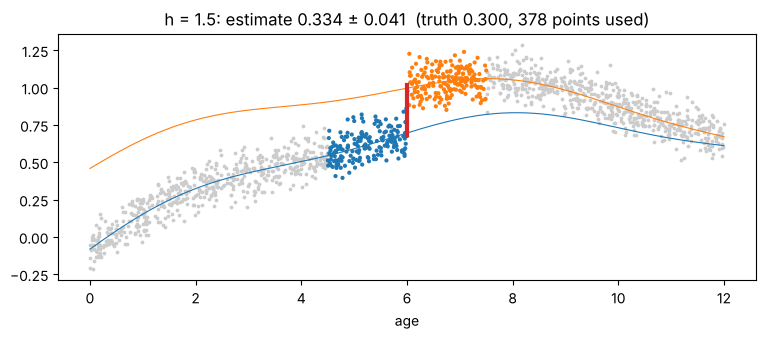

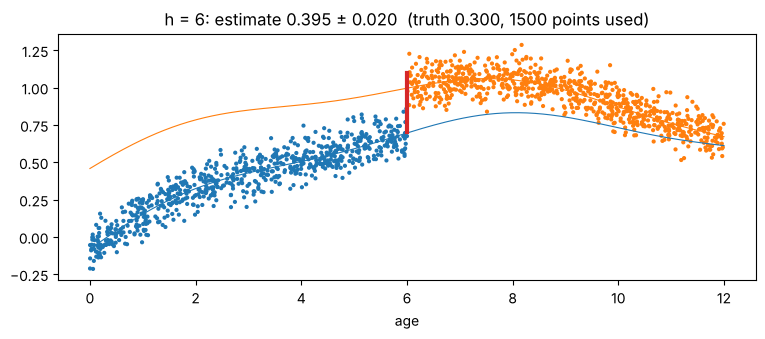

In [10]:
for h in [0.4, 1.5, 6.0]:
    bandwidth(h)

## What carries over

* IV and RDD are the course's two answers to unobserved confounding; [06](../../../06-structural-causal-models/) gives
  the graphical reasons (exclusion is a missing edge; RDD is a deterministic $T$ with a continuity assumption).
* Deep IV models reuse the "learn a nuisance, then plug it into a moment condition" pattern of
  [08 Orthogonal learning](../../../08-orthogonal-learning/).
* In [07](../../../07-causal-deep-learning/), RDD appears as "extrapolation for causal inference": the estimate is an ML
  prediction at the boundary, and the bandwidth is a hyper-parameter chosen by cross-validation.